In [1]:
import pandas as pd 
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns


In [2]:
data = 'https://raw.githubusercontent.com/DataTalksClub/machine-learning-zoomcamp/main/cohorts/2026/data/course_lead_scoring_2026.csv'

In [3]:
!wget $data

--2026-10-20 01:58:29--  https://raw.githubusercontent.com/DataTalksClub/machine-learning-zoomcamp/main/cohorts/2026/data/course_lead_scoring_2026.csv
Resolving raw.githubusercontent.com (raw.githubusercontent.com)... 185.199.111.133, 185.199.110.133, 185.199.109.133, ...
Connecting to raw.githubusercontent.com (raw.githubusercontent.com)|185.199.111.133|:443... connected.
HTTP request sent, awaiting response... 200 OK
Length: 278746 (272K) [text/plain]
Saving to: ‘course_lead_scoring_2026.csv.3’

course_lead_scoring 100%[===================>] 272.21K  --.-KB/s    in 0.1s    

2026-10-20 01:58:30 (2.60 MB/s) - ‘course_lead_scoring_2026.csv.3’ saved [278746/278746]



In [4]:
df = pd.read_csv(data)

In [5]:
df.dtypes



lead_source                     str
industry                        str
employment_status               str
location                        str
annual_income               float64
number_of_courses_viewed      int64
interaction_count             int64
lead_score                  float64
converted                     int64
dtype: object

In [6]:
categorical_features = ['lead_source','industry','employment_status','location']
numerical_features = ['annual_income', 'number_of_courses_viewed', 'interaction_count', 'lead_score']
df[categorical_features].head(5) 

,lead_source,industry,employment_status,location
0,organic_search,technology,employed,europe
1,social_media,technology,employed,south_america
2,referral,retail,employed,europe
3,paid_ads,manufacturing,student,NaN
4,referral,manufacturing,student,north_america


In [7]:
df[numerical_features].head(5)

,annual_income,number_of_courses_viewed,interaction_count,lead_score
0,88160.0,3,4,0.64
1,72688.0,3,7,0.72
2,44697.0,3,4,0.58
3,NaN,3,6,0.57
4,24062.0,4,5,0.62


In [8]:
df.isnull().sum()

lead_source                 148
industry                    240
employment_status           194
location                    208
annual_income               369
number_of_courses_viewed      0
interaction_count             0
lead_score                   35
converted                     0
dtype: int64

In [9]:
### Fill missing values of categorical feature by NA category 
df[categorical_features] = df[categorical_features].fillna('NA')

In [10]:
### Fill missing values of numerical feature by 0 
df[numerical_features] = df[numerical_features].fillna(0)

In [11]:
# Q1: What is the most frequent observation (mode) for the column industry?
df['industry'].value_counts().index[0]

'technology'

In [12]:
# q2: What are the two features that have the biggest correlation?
df[numerical_features].corr()

,annual_income,number_of_courses_viewed,interaction_count,lead_score
annual_income,1.000000,0.161300,0.122842,0.229496
number_of_courses_viewed,0.161300,1.000000,0.721609,0.757204
interaction_count,0.122842,0.721609,1.000000,0.915746
lead_score,0.229496,0.757204,0.915746,1.000000


In [13]:
from sklearn.model_selection import train_test_split
df_full_train, df_test = train_test_split(df, test_size=0.2, random_state=1)
df_train, df_val = train_test_split(
    df_full_train, test_size=0.25, random_state=1
)
print(len(df_full_train), len(df_train), len(df_val))
len(df_full_train), len(df_test)

4000 3000 1000


(4000, 1000)

In [14]:
df_train = df_train.reset_index(drop=True)
df_val = df_val.reset_index(drop=True)
df_test = df_test.reset_index(drop=True)

y_train = df_train.converted.values
y_val = df_val.converted.values
y_test = df_test.converted.values 

del df_train['converted']
del df_val['converted']
del df_test['converted']

In [15]:
from sklearn.metrics import mutual_info_score
def mutual_info_score_table(series):
    return mutual_info_score(series, y_train)

In [16]:
df_train[categorical_features].apply(mutual_info_score_table)

lead_source          0.032659
industry             0.003200
employment_status    0.022282
location             0.001436
dtype: float64

In [17]:
#Q3: Which of these variables has the biggest mutual information score?
mutual_info_table = df_train[categorical_features].apply(lambda col: mutual_info_score(col, y_train))
mutual_info_table.round(2).sort_values(ascending=False).index[0]


'lead_source'

In [18]:
from sklearn.feature_extraction import DictVectorizer

In [19]:
train_dicts = df_train.to_dict(orient="records")

In [20]:
dv = DictVectorizer(sparse=False)

In [21]:
dv.fit(train_dicts)

DictVectorizer(sparse=False)

In [22]:
dv.get_feature_names_out()

array(['annual_income', 'employment_status=NA',
       'employment_status=employed', 'employment_status=self_employed',
       'employment_status=student', 'employment_status=unemployed',
       'industry=NA', 'industry=education', 'industry=finance',
       'industry=healthcare', 'industry=manufacturing', 'industry=retail',
       'industry=technology', 'interaction_count', 'lead_score',
       'lead_source=NA', 'lead_source=events',
       'lead_source=organic_search', 'lead_source=paid_ads',
       'lead_source=referral', 'lead_source=social_media', 'location=NA',
       'location=africa', 'location=asia', 'location=europe',
       'location=north_america', 'location=south_america',
       'number_of_courses_viewed'], dtype=object)

In [23]:
X_train  = dv.transform(train_dicts)
X_train

array([[8.0198e+04, 0.0000e+00, 1.0000e+00, ..., 0.0000e+00, 0.0000e+00,
        5.0000e+00],
       [5.0548e+04, 0.0000e+00, 1.0000e+00, ..., 0.0000e+00, 0.0000e+00,
        2.0000e+00],
       [7.6300e+04, 0.0000e+00, 1.0000e+00, ..., 0.0000e+00, 0.0000e+00,
        0.0000e+00],
       ...,
       [2.1561e+04, 0.0000e+00, 0.0000e+00, ..., 0.0000e+00, 0.0000e+00,
        0.0000e+00],
       [3.1691e+04, 0.0000e+00, 0.0000e+00, ..., 0.0000e+00, 1.0000e+00,
        3.0000e+00],
       [4.6342e+04, 0.0000e+00, 0.0000e+00, ..., 0.0000e+00, 0.0000e+00,
        5.0000e+00]], shape=(3000, 28))

In [24]:
val_dicts = df_val.to_dict(orient="records")
X_val  = dv.transform(val_dicts)

In [25]:
from sklearn.linear_model import LogisticRegression

model = LogisticRegression(solver='liblinear', C=1.0, max_iter=1000, random_state=42)
model.fit(X_train, y_train)

,"random_state random_state: int, RandomState instance, default=NoneOnly used for `solver` == 'sag', 'saga' or 'liblinear' to shuffle thedata. It has no effect on the other solvers.See :term:`Glossary <random_state>` for details.",42
,"solver solver: {'lbfgs', 'liblinear', 'newton-cg', 'newton-cholesky', 'sag', 'saga'}, default='lbfgs'Algorithm to use in the optimization problem. Default is 'lbfgs'.To choose a solver, you might want to consider the following aspects:- 'lbfgs' is a good default solver because it works reasonably well for a wide class of problems.- For :term:`multiclass` problems (`n_classes >= 3`), all solvers except 'liblinear' minimize the full multinomial loss, 'liblinear' will raise an error.- 'newton-cholesky' is a good choice for `n_samples` >> `n_features * n_classes`, especially with one-hot encoded categorical features with rare categories. Be aware that the memory usage of this solver has a quadratic dependency on `n_features * n_classes` because it explicitly computes the full Hessian matrix.- For small datasets, 'liblinear' is a good choice, whereas 'sag' and 'saga' are faster for large ones;- 'liblinear' can only handle binary classification by default. To apply a one-versus-rest scheme for the multiclass setting one can wrap it with the :class:`~sklearn.multiclass.OneVsRestClassifier`... warning:: The choice of the algorithm depends on the penalty chosen (`l1_ratio=0` for L2-penalty, `l1_ratio=1` for L1-penalty and `0 < l1_ratio < 1` for Elastic-Net) and on (multinomial) multiclass support: ================= ======================== ====================== solver l1_ratio multinomial multiclass ================= ======================== ====================== 'lbfgs' l1_ratio=0 yes 'liblinear' l1_ratio=1 or l1_ratio=0 no 'newton-cg' l1_ratio=0 yes 'newton-cholesky' l1_ratio=0 yes 'sag' l1_ratio=0 yes 'saga' 0<=l1_ratio<=1 yes ================= ======================== ======================.. note:: 'sag' and 'saga' fast convergence is only guaranteed on features with approximately the same scale. You can preprocess the data with a scaler from :mod:`sklearn.preprocessing`... seealso:: Refer to the :ref:`User Guide <Logistic_regression>` for more information regarding :class:`LogisticRegression` and more specifically the :ref:`Table <logistic_regression_solvers>` summarizing solver/penalty supports... versionadded:: 0.17 Stochastic Average Gradient (SAG) descent solver. Multinomial support in version 0.18... versionadded:: 0.19 SAGA solver... versionchanged:: 0.22 The default solver changed from 'liblinear' to 'lbfgs' in 0.22... versionadded:: 1.2 newton-cholesky solver. Multinomial support in version 1.6.",'liblinear'
,"max_iter max_iter: int, default=100Maximum number of iterations taken for the solvers to converge.",1000
,"penalty penalty: {'l1', 'l2', 'elasticnet', None}, default='l2'Specify the norm of the penalty:- `None`: no penalty is added;- `'l2'`: add an L2 penalty term and it is the default choice;- `'l1'`: add an L1 penalty term;- `'elasticnet'`: both L1 and L2 penalty terms are added... warning:: Some penalties may not work with some solvers. See the parameter `solver` below, to know the compatibility between the penalty and solver... versionadded:: 0.19 l1 penalty with SAGA solver (allowing 'multinomial' + L1).. deprecated:: 1.8 `penalty` was deprecated in version 1.8 and will be removed in 1.10. Use `l1_ratio` and `C` instead. `l1_ratio=0` for `penalty='l2'`, `l1_ratio=1` for `penalty='l1'`, `l1_ratio` set to any float between 0 and 1 for `penalty='elasticnet'`, and `C=np.inf` for `penalty=None`.",'deprecated'
,"C C: float, default=1.0Inverse of regularization strength; must be a positive float.Like in support vector machines, smaller values specify strongerregularization. `C=np.inf` results in unpenalized logistic regression.For a visual example on the effect of tuning the `C` parameterwith an L1 penalty, see::ref:`sphx_glr_auto_examples_linear_model_plot_logistic_path.py`.",1.0
,"l

In [26]:
model.coef_, model.intercept_

(array([[-1.11069612e-05, -1.03126714e-03,  3.31288674e-02,
         -2.27487242e-02, -5.51988639e-02, -4.70315064e-02,
         -3.51321094e-03, -2.50360020e-02, -1.15823347e-02,
         -2.35956862e-02, -9.11451316e-03, -3.18372849e-02,
          1.17975376e-02,  2.52486316e-01,  1.90711703e-02,
         -1.99342257e-03, -4.06584837e-02,  1.26754111e-02,
         -6.50773139e-02,  2.74997413e-02, -2.53274266e-02,
         -4.95488356e-03, -2.00226983e-02, -1.45889034e-02,
         -9.73838505e-03, -2.21940087e-02, -2.13826153e-02,
          1.04919208e-01]]),
 array([-0.09288149]))

In [27]:
y_pred = model.predict_proba(X_val)[:,1]

In [28]:
converted = (y_pred >=0.5)

In [29]:
df_pred = pd.DataFrame()
df_pred['probability'] = y_pred
df_pred['pred'] =  converted.astype(int)
df_pred['real']= y_val
df_pred['correct'] = df_pred.pred == df_pred.real
df_pred

,probability,pred,real,correct
0,0.544723,1,0,False
1,0.790052,1,1,True
2,0.509779,1,1,True
3,0.529139,1,1,True
4,0.820720,1,0,False
...,...,...,...,...
995,0.741848,1,1,True
996,0.657033,1,1,True
997,0.757786,1,1,True
998,0.779014,1,1,True


In [30]:
#Q4:What accuracy did you get?
accuracy = df_pred.correct.mean()
round(float(accuracy), 2) 

0.65

In [31]:
accuracy

np.float64(0.651)

In [32]:
# ----------------------------------------Question 5 -----------------------------------------------------
# Which of following feature has the smallest difference? 

In [33]:
def train_and_score(features):
    dv = DictVectorizer(sparse=False)
    X_train = dv.fit_transform(df_train[features].to_dict(orient="records"))
    X_val = dv.transform(df_val[features].to_dict(orient="records"))

    model = LogisticRegression(solver="liblinear", C=1.0, max_iter=1000, random_state=42)
    model.fit(X_train, y_train)
    y_pred = model.predict(X_val)
    correct = y_pred == y_val
    accuracy = correct.mean()
    return accuracy

In [34]:
original_acc = train_and_score(categorical_features +  numerical_features)
print("original accuracy:", original_acc)

original accuracy: 0.651


In [35]:
total_features = categorical_features +  numerical_features
total_features
results = []
for features in total_features:
    subset = [x for x in total_features if x != features]
    acc = train_and_score(subset)
    results.append({
        "feature": features,
        "accuracy_without": acc,
        "difference": original_acc - acc,
    })
diff_df = pd.DataFrame(results).sort_values("difference")
print(diff_df)

                    feature  accuracy_without  difference
4             annual_income             0.716      -0.065
1                  industry             0.651       0.000
7                lead_score             0.651       0.000
3                  location             0.650       0.001
2         employment_status             0.648       0.003
0               lead_source             0.648       0.003
5  number_of_courses_viewed             0.645       0.006
6         interaction_count             0.593       0.058


In [36]:
# # ----------------------------------------Question 6 -----------------------------------------------------
# Which of these C leads to the best accuracy on the validation set?

In [37]:
def train_and_score(features, C=1.0):
    dv = DictVectorizer(sparse=False)
    X_train = dv.fit_transform(df_train[features].to_dict(orient="records"))
    X_val = dv.transform(df_val[features].to_dict(orient="records"))

    model = LogisticRegression(solver="liblinear", C=C, max_iter=1000, random_state=42)
    model.fit(X_train, y_train)
    y_pred = model.predict(X_val)
    return (y_pred == y_val).mean()

In [38]:
total_features = categorical_features + numerical_features

results = []
for C in [0.000001, 0.00001, 0.0001, 0.001]:
    acc = train_and_score(total_features, C=C)
    results.append({
        "C": C,
        "accuracy": round(float(acc), 3),
    })

c_df = pd.DataFrame(results).sort_values("accuracy")
c_df

,C,accuracy
0,0.000001,0.590
1,0.000010,0.590
2,0.000100,0.590
3,0.001000,0.648


In [39]:
## Homework 4
# Q1: Which numerical variable (among the following 4) has the highest AUC?
from sklearn.metrics import roc_auc_score

auc_scores = {}
for col in numerical_features:
    auc = roc_auc_score(y_train, df_train[col])
    if auc < 0.5:
        auc = roc_auc_score(y_train, -df_train[col])
    auc_scores[col] = auc

auc_df = pd.Series(auc_scores).sort_values(ascending=False)
print(auc_df.round(4))
auc_df.index[0]

lead_score                  0.7882
interaction_count           0.7649
number_of_courses_viewed    0.7230
annual_income               0.6082
dtype: float64


'lead_score'

In [40]:
# Q2 What's the AUC of
features = categorical_features + numerical_features

dv = DictVectorizer(sparse=False)
X_train = dv.fit_transform(df_train[features].to_dict(orient="records"))
X_val = dv.transform(df_val[features].to_dict(orient="records"))

model = LogisticRegression(solver='liblinear', C=1.0, max_iter=1000)
model.fit(X_train, y_train)

y_pred = model.predict_proba(X_val)[:, 1]



In [41]:
auc = roc_auc_score(y_val, y_pred)
round(auc, 3) 

0.732

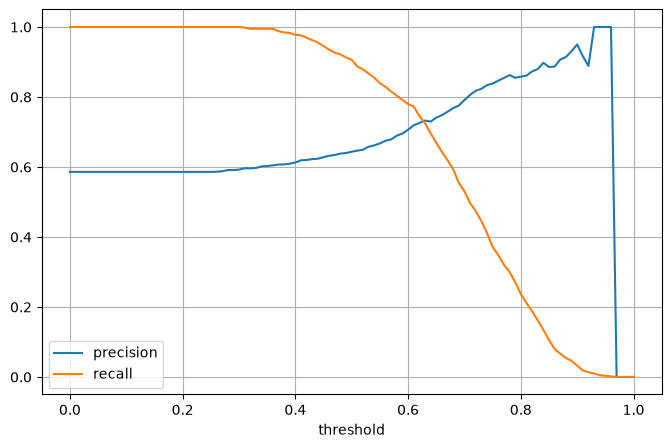

,threshold,precision,recall,diff
63,0.63,0.732759,0.725256,0.007503
62,0.62,0.725914,0.745734,0.019820
64,0.64,0.729875,0.696246,0.033629
61,0.61,0.719048,0.773038,0.053990
65,0.65,0.741021,0.668942,0.072079


In [42]:
#Q3: At which threshold precision and recall curves intersect? Ignore thresholds at which both metrics are zero, and choose the threshold with the smallest absolute difference between precision and recall.
thresholds = np.arange(0.0, 1.01, 0.01)
scores = []

for t in thresholds:
    predict_positive = (y_pred >= t)
    actual_positive = (y_val == 1)

    tp = (predict_positive & actual_positive).sum()
    fp = (predict_positive & ~actual_positive).sum()
    fn = (~predict_positive & actual_positive).sum()

    precision = tp / (tp + fp) if (tp + fp) > 0 else 0
    recall = tp / (tp + fn) if (tp + fn) > 0 else 0
    scores.append((round(t, 2), precision, recall))

df_scores = pd.DataFrame(scores, columns=['threshold', 'precision', 'recall'])

plt.figure(figsize=(8, 5))
plt.plot(df_scores.threshold, df_scores.precision, label='precision')
plt.plot(df_scores.threshold, df_scores.recall, label='recall')
plt.xlabel('threshold')
plt.legend()
plt.grid(True)
plt.show()

# ignore thresholds where both metrics are zero
df_valid = df_scores[(df_scores.precision > 0) | (df_scores.recall > 0)].copy()
df_valid['diff'] = (df_valid.precision - df_valid.recall).abs()
df_valid.sort_values('diff').head()

In [43]:
#  Q4:Let's compute F1 for all thresholds from 0.0 to 1.0 with increment 0.01 At which threshold F1 is maximal? \
df_scores['f1'] = np.where(
    (df_scores.precision + df_scores.recall) > 0,
    2 * df_scores.precision * df_scores.recall / (df_scores.precision + df_scores.recall),
    0
)

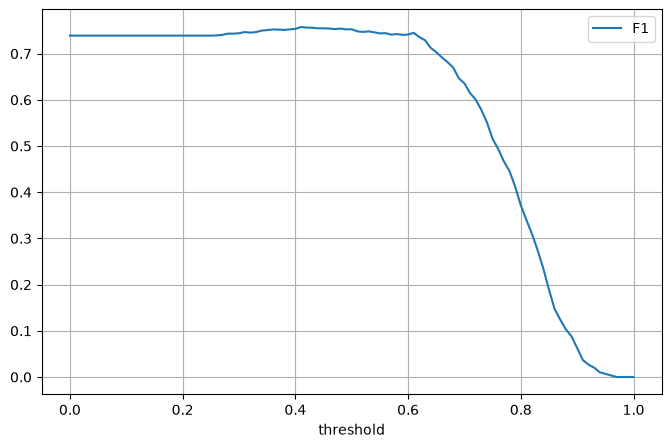

,threshold,precision,recall,f1
41,0.41,0.619048,0.976109,0.757616
42,0.42,0.620087,0.969283,0.756325
43,0.43,0.622517,0.962457,0.756032
45,0.45,0.628118,0.945392,0.754768
44,0.44,0.623608,0.955631,0.754717


In [44]:
plt.figure(figsize=(8, 5))
plt.plot(df_scores.threshold, df_scores.f1, label='F1')
plt.xlabel('threshold')
plt.legend()
plt.grid(True)
plt.show()

df_scores.sort_values('f1', ascending=False).head()

In [45]:
#Q5 : How large is standard deviation of the scores across different folds?
from sklearn.model_selection import KFold

In [46]:
def train(df, y, C=1.0):
    dv = DictVectorizer(sparse=False)
    X = dv.fit_transform(df[features].to_dict(orient="records"))
    model = LogisticRegression(solver='liblinear', C=C, max_iter=1000)
    model.fit(X, y)
    return dv, model

def predict(df, dv, model):
    X = dv.transform(df[features].to_dict(orient="records"))
    return model.predict_proba(X)[:, 1]

In [47]:
kfold = KFold(n_splits=5, shuffle=True, random_state=1)
scores = []

for train_idx, val_idx in kfold.split(df_full_train):
    df_tr = df_full_train.iloc[train_idx]
    df_va = df_full_train.iloc[val_idx]

    y_tr = df_tr.converted.values
    y_va = df_va.converted.values

    dv, model = train(df_tr, y_tr)
    y_pred = predict(df_va, dv, model)
    scores.append(roc_auc_score(y_va, y_pred))

print(np.round(scores, 3))
print(f"mean = {np.mean(scores):.3f}, std = {np.std(scores):.3f}")

[0.731 0.73  0.736 0.741 0.721]
mean = 0.732, std = 0.007


In [48]:
# Q6 : Which C leads to the best mean ROC AUC?
kfold = KFold(n_splits=5, shuffle=True, random_state=1)


In [49]:
for C in [0.000001, 0.001, 1]:
    scores = []

    for train_idx, val_idx in kfold.split(df_full_train):
        df_tr = df_full_train.iloc[train_idx]
        df_va = df_full_train.iloc[val_idx]

        y_tr = df_tr.converted.values
        y_va = df_va.converted.values

        dv, model = train(df_tr, y_tr, C=C)
        y_pred = predict(df_va, dv, model)
        scores.append(roc_auc_score(y_va, y_pred))

    print(f"C={C}: mean = {np.mean(scores):.3f}, std = {np.std(scores):.3f}")

C=1e-06: mean = 0.617, std = 0.019
C=0.001: mean = 0.749, std = 0.010
C=1: mean = 0.732, std = 0.007
